In [54]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/dayanithaam/gridmet/bi_2021.nc
/kaggle/input/datasets/dayanithaam/gridmet/etr_2021.nc
/kaggle/input/datasets/dayanithaam/gridmet/pr_2021.nc
/kaggle/input/datasets/dayanithaam/gridmet/rmax_2021.nc
/kaggle/input/datasets/dayanithaam/gridmet/rmin_2021.nc
/kaggle/input/datasets/dayanithaam/gridmet/srad_2021.nc
/kaggle/input/datasets/dayanithaam/gridmet/tmmn_2021.nc
/kaggle/input/datasets/dayanithaam/gridmet/tmmx_2021.nc


Dataset inspection


In [55]:
import os

DATA_DIR = "/kaggle/input/datasets/dayanithaam/gridmet"

for file in os.listdir(DATA_DIR):
    if file.endswith(".nc"):
        print(file)

bi_2021.nc
etr_2021.nc
pr_2021.nc
rmax_2021.nc
rmin_2021.nc
srad_2021.nc
tmmn_2021.nc
tmmx_2021.nc


In [56]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

In [57]:
for file in os.listdir(DATA_DIR):

    if file.endswith(".nc"):

        path = os.path.join(DATA_DIR, file)
        ds = xr.open_dataset(path)

        print("\n" + "="*60)
        print("FILE:", file)
        print("="*60)

        print(ds)
        print("\nDimensions:", ds.dims)
        print("\nCoordinates:", list(ds.coords))
        print("\nData variables:", list(ds.data_vars))

        for var in ds.data_vars:
            print("\nVariable:", var)
            print("Attributes:", ds[var].attrs)


FILE: bi_2021.nc
<xarray.Dataset> Size: 2GB
Dimensions:          (day: 365, lat: 585, lon: 1386, crs: 1)
Coordinates:
  * day              (day) datetime64[ns] 3kB 2021-01-01 ... 2021-12-31
  * lat              (lat) float64 5kB 49.4 49.36 49.32 ... 25.15 25.11 25.07
  * lon              (lon) float64 11kB -124.8 -124.7 -124.7 ... -67.1 -67.06
  * crs              (crs) uint16 2B 3
Data variables:
    burning_index_g  (day, lat, lon) float64 2GB ...
Attributes: (12/19)
    geospatial_bounds_crs:      EPSG:4326
    Conventions:                CF-1.6
    geospatial_bounds:          POLYGON((-124.7666666333333 49.40000000000000...
    geospatial_lat_min:         25.066666666666666
    geospatial_lat_max:         49.40000000000000
    geospatial_lon_min:         -124.7666666333333
    ...                         ...
    date:                       07 April 2025
    note1:                      The projection information for this file is: ...
    note2:                      Citation: Abatzo

In [58]:
import os
import xarray as xr

OUTPUT_DIR = "/kaggle/working/july_september_2021"

os.makedirs(OUTPUT_DIR, exist_ok=True)

for file in os.listdir(DATA_DIR):

    if file.endswith(".nc"):

        path = os.path.join(DATA_DIR, file)

        ds = xr.open_dataset(path)

        # Identify time dimension
        time_dim = next(
            dim for dim in ds.dims
            if dim.lower() in ["day", "time"]
        )

        # Extract July 1 to September 30
        extracted = ds.sel({
            time_dim: slice("2021-07-01", "2021-09-30")
        })

        # Save extracted data
        output_path = os.path.join(
            OUTPUT_DIR,
            file.replace(".nc", "_Jul_Sep_2021.nc")
        )

        extracted.to_netcdf(output_path)

        print(file, "->", extracted.sizes)

bi_2021.nc -> Frozen({'day': 92, 'lat': 585, 'lon': 1386, 'crs': 1})
etr_2021.nc -> Frozen({'day': 92, 'lat': 585, 'lon': 1386, 'crs': 1})
pr_2021.nc -> Frozen({'day': 92, 'lat': 585, 'lon': 1386, 'crs': 1})
rmax_2021.nc -> Frozen({'day': 92, 'lat': 585, 'lon': 1386, 'crs': 1})
rmin_2021.nc -> Frozen({'day': 92, 'lat': 585, 'lon': 1386, 'crs': 1})
srad_2021.nc -> Frozen({'day': 92, 'lat': 585, 'lon': 1386, 'crs': 1})
tmmn_2021.nc -> Frozen({'day': 92, 'lat': 585, 'lon': 1386, 'crs': 1})
tmmx_2021.nc -> Frozen({'day': 92, 'lat': 585, 'lon': 1386, 'crs': 1})


In [59]:
for file in os.listdir(OUTPUT_DIR):

    path = os.path.join(OUTPUT_DIR, file)

    ds = xr.open_dataset(path)

    time_dim = next(
        dim for dim in ds.dims
        if dim.lower() in ["day", "time"]
    )

    print("\nFile:", file)
    print("Dimensions:", ds.sizes)
    print("Start date:", ds[time_dim].values[0])
    print("End date:", ds[time_dim].values[-1])


File: tmmn_2021_Jul_Sep_2021.nc
Dimensions: Frozen({'day': 92, 'lat': 585, 'lon': 1386, 'crs': 1})
Start date: 2021-07-01T00:00:00.000000000
End date: 2021-09-30T00:00:00.000000000

File: pr_2021_Jul_Sep_2021.nc
Dimensions: Frozen({'day': 92, 'lat': 585, 'lon': 1386, 'crs': 1})
Start date: 2021-07-01T00:00:00.000000000
End date: 2021-09-30T00:00:00.000000000

File: bi_2021_Jul_Sep_2021.nc
Dimensions: Frozen({'day': 92, 'lat': 585, 'lon': 1386, 'crs': 1})
Start date: 2021-07-01T00:00:00.000000000
End date: 2021-09-30T00:00:00.000000000

File: etr_2021_Jul_Sep_2021.nc
Dimensions: Frozen({'day': 92, 'lat': 585, 'lon': 1386, 'crs': 1})
Start date: 2021-07-01T00:00:00.000000000
End date: 2021-09-30T00:00:00.000000000

File: tmmx_2021_Jul_Sep_2021.nc
Dimensions: Frozen({'day': 92, 'lat': 585, 'lon': 1386, 'crs': 1})
Start date: 2021-07-01T00:00:00.000000000
End date: 2021-09-30T00:00:00.000000000

File: rmin_2021_Jul_Sep_2021.nc
Dimensions: Frozen({'day': 92, 'lat': 585, 'lon': 1386, 'crs':

Statistical Analysis for the variables

In [60]:
import os
import xarray as xr
import pandas as pd
import numpy as np

summary = []

for file in os.listdir(OUTPUT_DIR):

    if file.endswith(".nc"):

        ds = xr.open_dataset(os.path.join(OUTPUT_DIR, file))

        for var in ds.data_vars:

            data = ds[var]

            summary.append({
                "Variable": var,
                "Units": data.attrs.get("units", "Unknown"),
                "Minimum": float(data.min(skipna=True)),
                "Maximum": float(data.max(skipna=True)),
                "Mean": float(data.mean(skipna=True)),
                "Std Dev": float(data.std(skipna=True)),
                "Missing Values": int(data.isnull().sum())
            })

summary_df = pd.DataFrame(summary)

display(summary_df)

,Variable,Units,Minimum,Maximum,Mean,Std Dev,Missing Values
0,air_temperature,K,261.2,312.5,288.372587,5.761062,30077652
1,precipitation_amount,mm,0.0,336.1,2.614597,8.227417,30077652
2,burning_index_g,Unitless,0.0,155.0,29.459257,23.392315,30077652
3,potential_evapotranspiration,mm,0.2,27.5,6.900235,2.375300,30077652
4,air_temperature,K,264.9,327.3,302.166105,5.451529,30077652
5,relative_humidity,%,1.0,100.0,35.969618,17.634972,30077652
6,relative_humidity,%,10.1,100.0,81.348204,19.657084,30077652
7,surface_downwelling_shortwave_flux_in_air,W m-2,29.3,450.9,254.686636,54.648938,30077652


MAX_TEMPERATURE


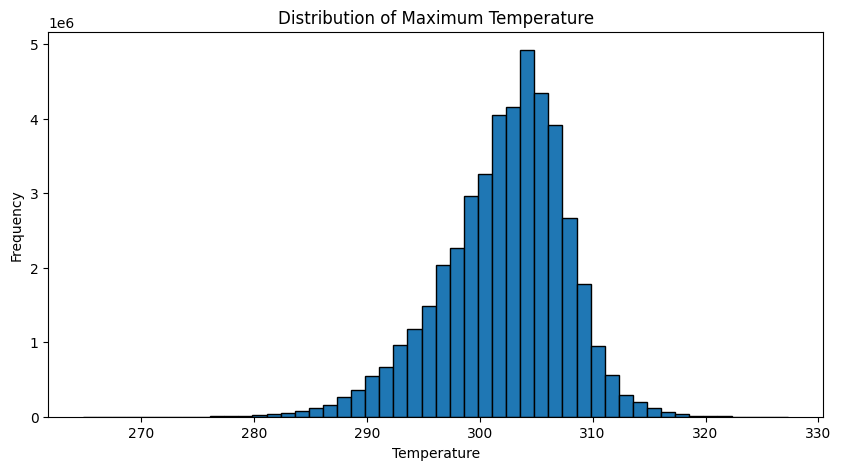

In [61]:
ds = xr.open_dataset(
    os.path.join(OUTPUT_DIR, "tmmx_2021_Jul_Sep_2021.nc")
)

var = list(ds.data_vars)[0]
data = ds[var]

plt.figure(figsize=(10, 5))

values = data.values.flatten()
values = values[np.isfinite(values)]

plt.hist(values, bins=50, edgecolor='black')

plt.xlabel("Temperature")
plt.ylabel("Frequency")
plt.title("Distribution of Maximum Temperature")

plt.show()

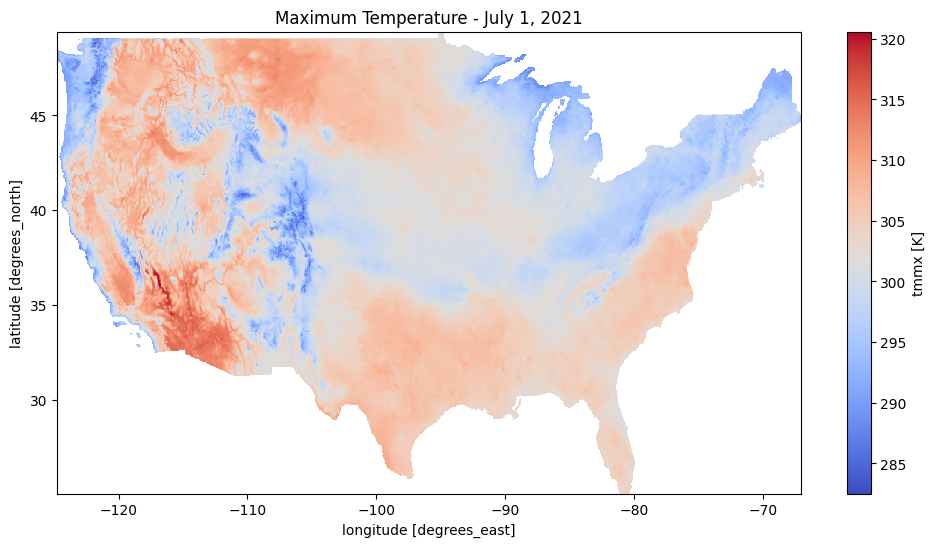

In [62]:
plt.figure(figsize=(12, 6))

data.isel(day=0).plot(
    cmap="coolwarm"
)

plt.title("Maximum Temperature - July 1, 2021")
plt.show()

In [63]:
# Calculate spatial average temperature for every day
tmmx = ds["air_temperature"].sel(day=slice("2021-07-01", "2021-09-30"))
daily_avg_temp = tmmx.mean(dim=["lat", "lon"], skipna=True)

# Find the day with the highest average temperature
hottest_idx = daily_avg_temp.argmax(dim="day").item()

hottest_date = pd.to_datetime(tmmx.day.values[hottest_idx])
highest_avg_temp = float(daily_avg_temp.isel(day=hottest_idx))

print("Date with highest overall average temperature:",
      hottest_date.strftime("%d %B %Y"))

print("Highest average temperature:", round(highest_avg_temp, 2), "K")
print("Highest average temperature in Celsius:",
      round(highest_avg_temp - 273.15, 2), "°C")


Date with highest overall average temperature: 26 July 2021
Highest average temperature: 305.25 K
Highest average temperature in Celsius: 32.1 °C


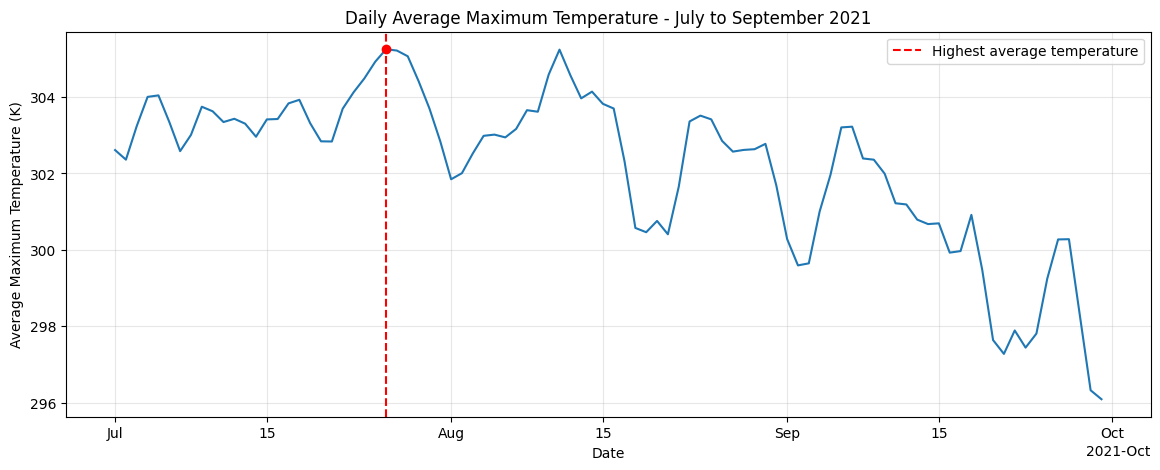

In [64]:
plt.figure(figsize=(14, 5))

daily_avg_temp.plot()

plt.axvline(
    x=tmmx.day.values[hottest_idx],
    color="red",
    linestyle="--",
    label="Highest average temperature"
)

plt.scatter(
    tmmx.day.values[hottest_idx],
    highest_avg_temp,
    color="red",
    zorder=5
)

plt.title("Daily Average Maximum Temperature - July to September 2021")
plt.xlabel("Date")
plt.ylabel("Average Maximum Temperature (K)")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("/kaggle/working/tmmx_daily_average.png",
            dpi=300, bbox_inches="tight")

plt.show()

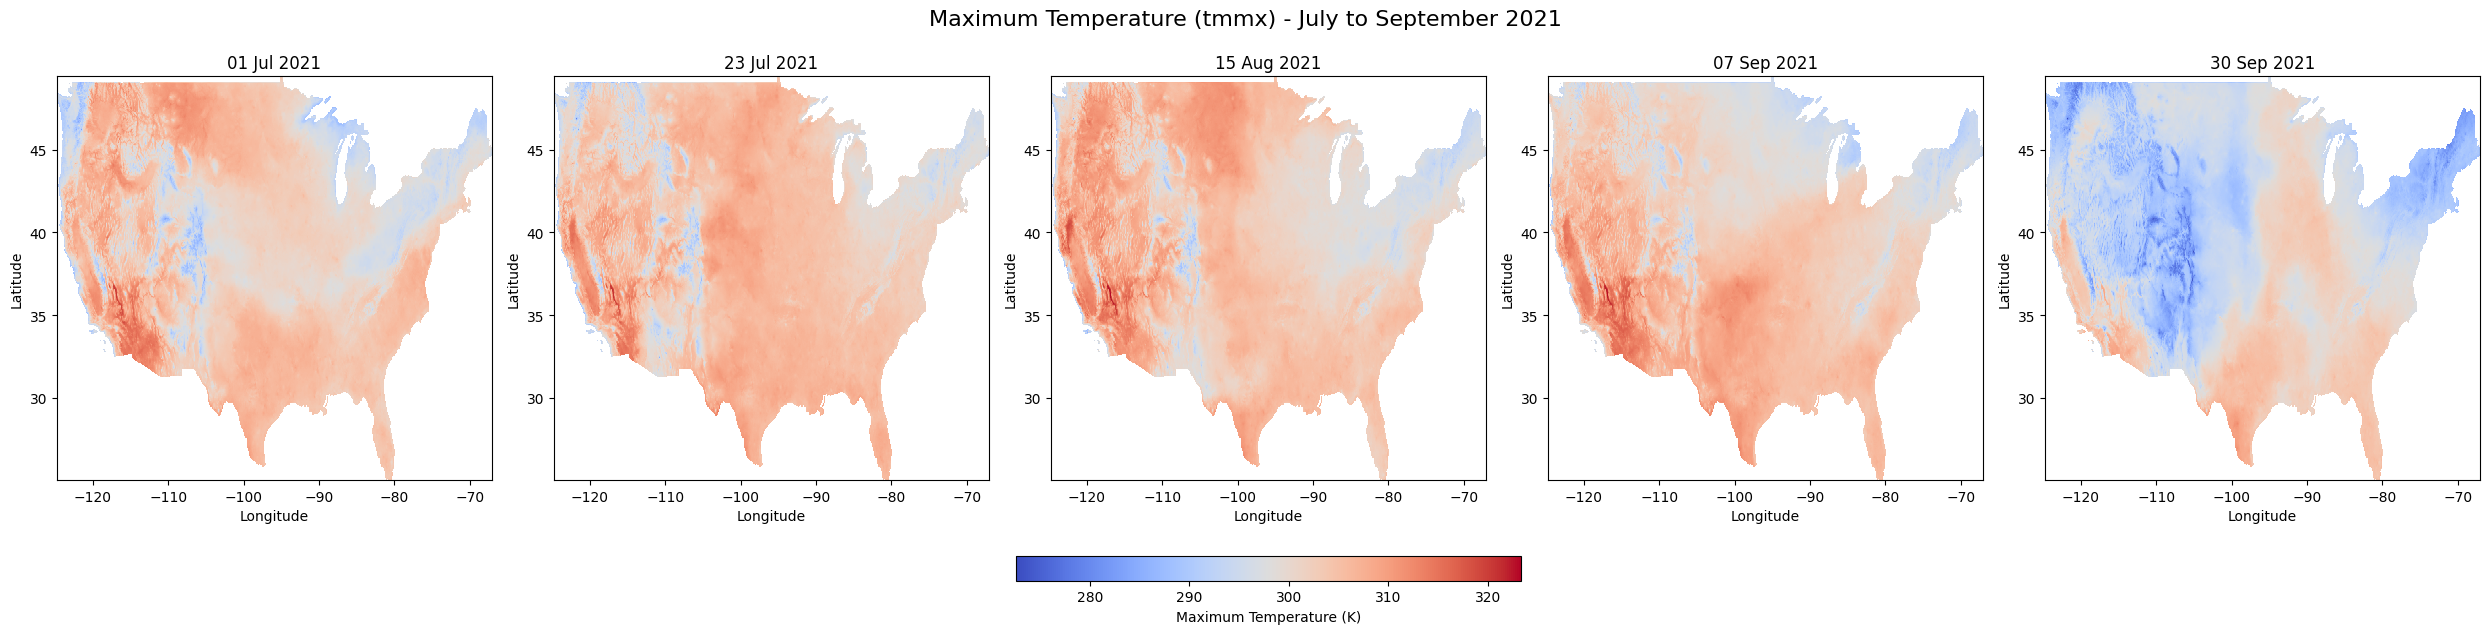

In [65]:
#GLOBAL MAPPING
file_path = "/kaggle/input/datasets/dayanithaam/gridmet/tmmx_2021.nc"
ds = xr.open_dataset(file_path)

# Extract maximum temperature for July-September 2021
tmmx = ds["air_temperature"].sel(day=slice("2021-07-01", "2021-09-30"))

# Select 5 evenly spaced time instances
indices = np.linspace(0, len(tmmx.day) - 1, 5, dtype=int)

# Calculate common global minimum and maximum for colour scaling
global_min = float(tmmx.isel(day=indices).min())
global_max = float(tmmx.isel(day=indices).max())

# Plot all 5 time instances
fig, axes = plt.subplots(1, 5, figsize=(25, 6))

for i, idx in enumerate(indices):
    date = pd.to_datetime(tmmx.day.values[idx]).strftime("%d %b %Y")

    img = tmmx.isel(day=idx).plot(
        ax=axes[i],
        cmap="coolwarm",
        vmin=global_min,
        vmax=global_max,
        add_colorbar=False
    )

    axes[i].set_title(date)
    axes[i].set_xlabel("Longitude")
    axes[i].set_ylabel("Latitude")

# Add one common colour bar
plt.tight_layout()
cbar = fig.colorbar(img, ax=axes, orientation="horizontal",
                    fraction=0.05, pad=0.15)
cbar.set_label("Maximum Temperature (K)")

plt.suptitle("Maximum Temperature (tmmx) - July to September 2021",
             fontsize=16, y=1.05)

plt.savefig("/kaggle/working/tmmx_global_mapping.png",
            dpi=300, bbox_inches="tight")

plt.show()

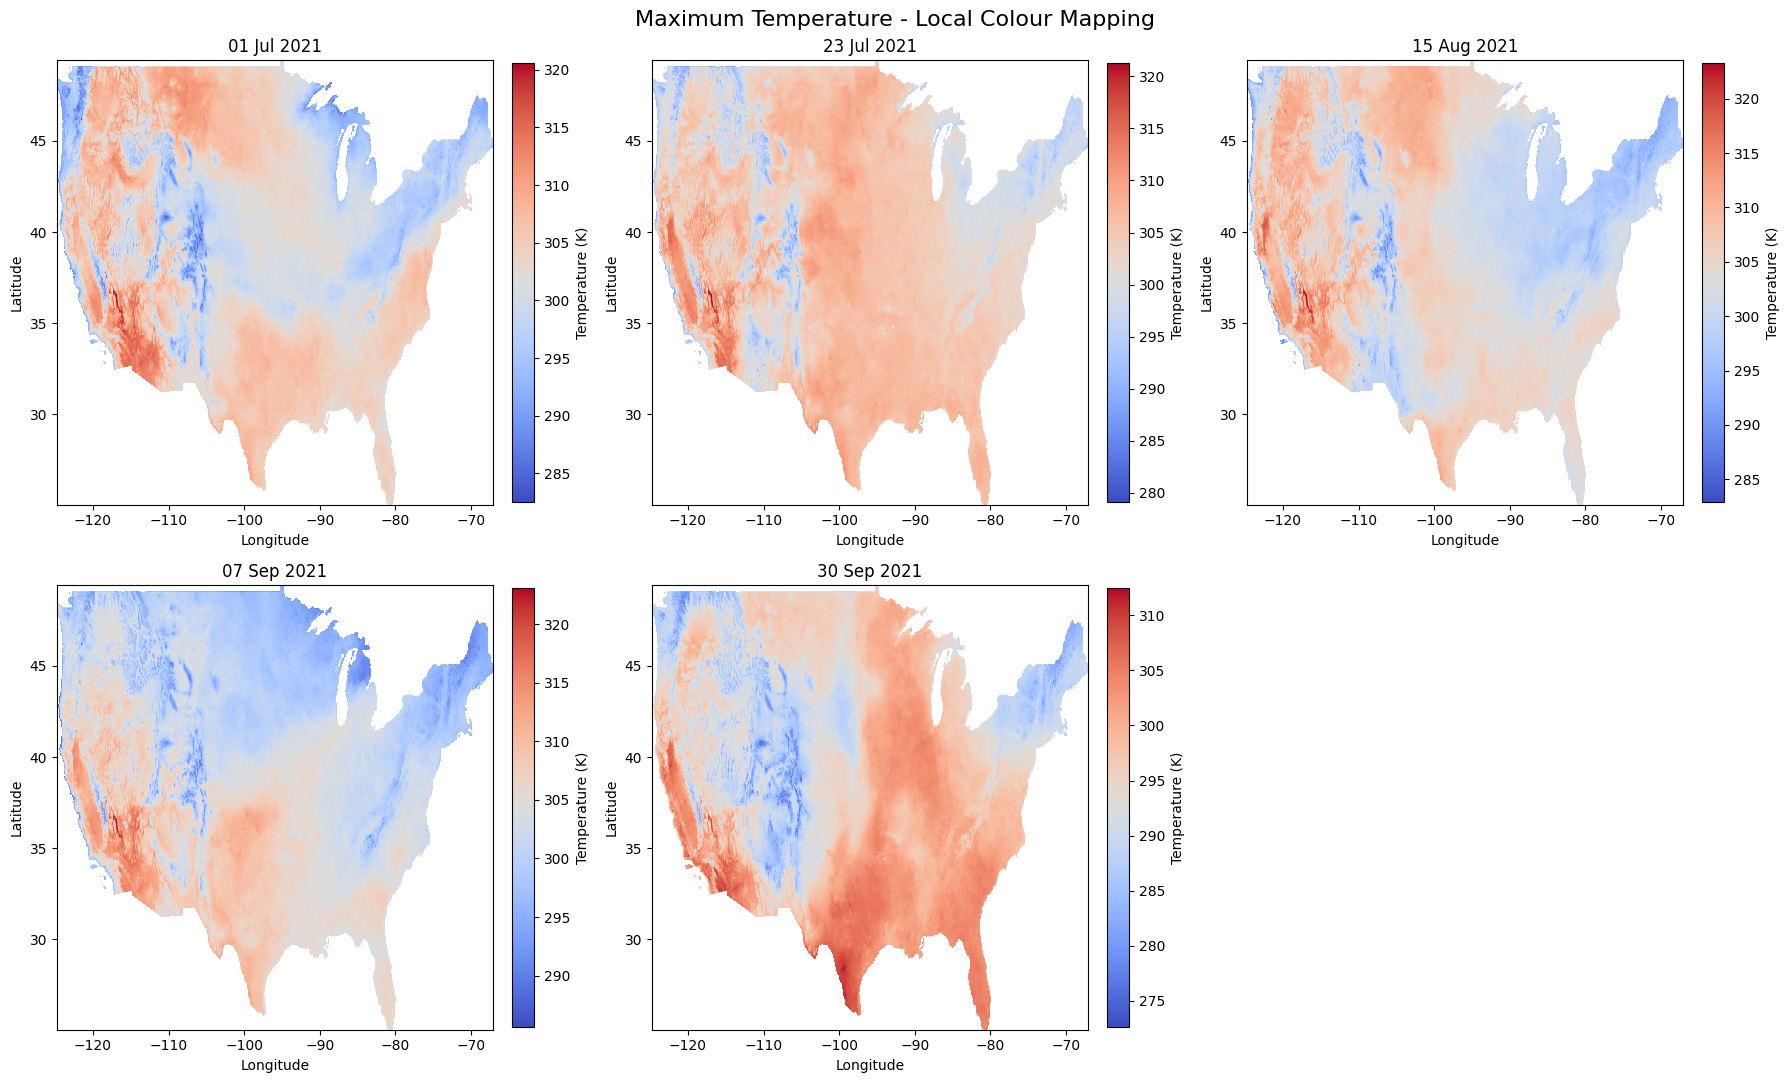

In [66]:
#LOCAL MAPPING USING SEQUENTIAL COLOUR MAPS
# Select the same 5 time instances

indices = np.linspace(0, len(tmmx.day) - 1, 5, dtype=int)

# Create a 2 x 3 layout
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, idx in enumerate(indices):

    daily_data = tmmx.isel(day=idx)

    # Local minimum and maximum
    local_min = float(daily_data.min())
    local_max = float(daily_data.max())

    date = pd.to_datetime(tmmx.day.values[idx]).strftime("%d %b %Y")

    img = daily_data.plot(
        ax=axes[i],
        cmap="coolwarm",
        vmin=local_min,
        vmax=local_max,
        add_colorbar=False
    )

    axes[i].set_title(date, fontsize=12)
    axes[i].set_xlabel("Longitude")
    axes[i].set_ylabel("Latitude")

    # Individual colour bar
    sm = plt.cm.ScalarMappable(
        cmap="coolwarm",
        norm=plt.Normalize(vmin=local_min, vmax=local_max)
    )

    fig.colorbar(sm, ax=axes[i], fraction=0.046, pad=0.04,
                 label="Temperature (K)")

# Remove the unused sixth subplot
fig.delaxes(axes[5])

plt.suptitle("Maximum Temperature - Local Colour Mapping",
             fontsize=16)

plt.tight_layout()

plt.savefig("/kaggle/working/tmmx_local_mapping.png",
            dpi=300, bbox_inches="tight")

plt.show()

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2553: RuntimeWarning: invalid value encountered in ? (vectorized)
  outputs = ufunc(*inputs)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2553: RuntimeWarning: invalid value encountered in ? (vectorized)
  outputs = ufunc(*inputs)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2553: RuntimeWarning: invalid value encountered in ? (vectorized)
  outputs = ufunc(*inputs)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2553: RuntimeWarning: invalid value encountered in ? (vectorized)
  outputs = ufunc(*inputs)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2553: RuntimeWarning: invalid value encountered in ? (vectorized)
  outputs = ufunc(*inputs)


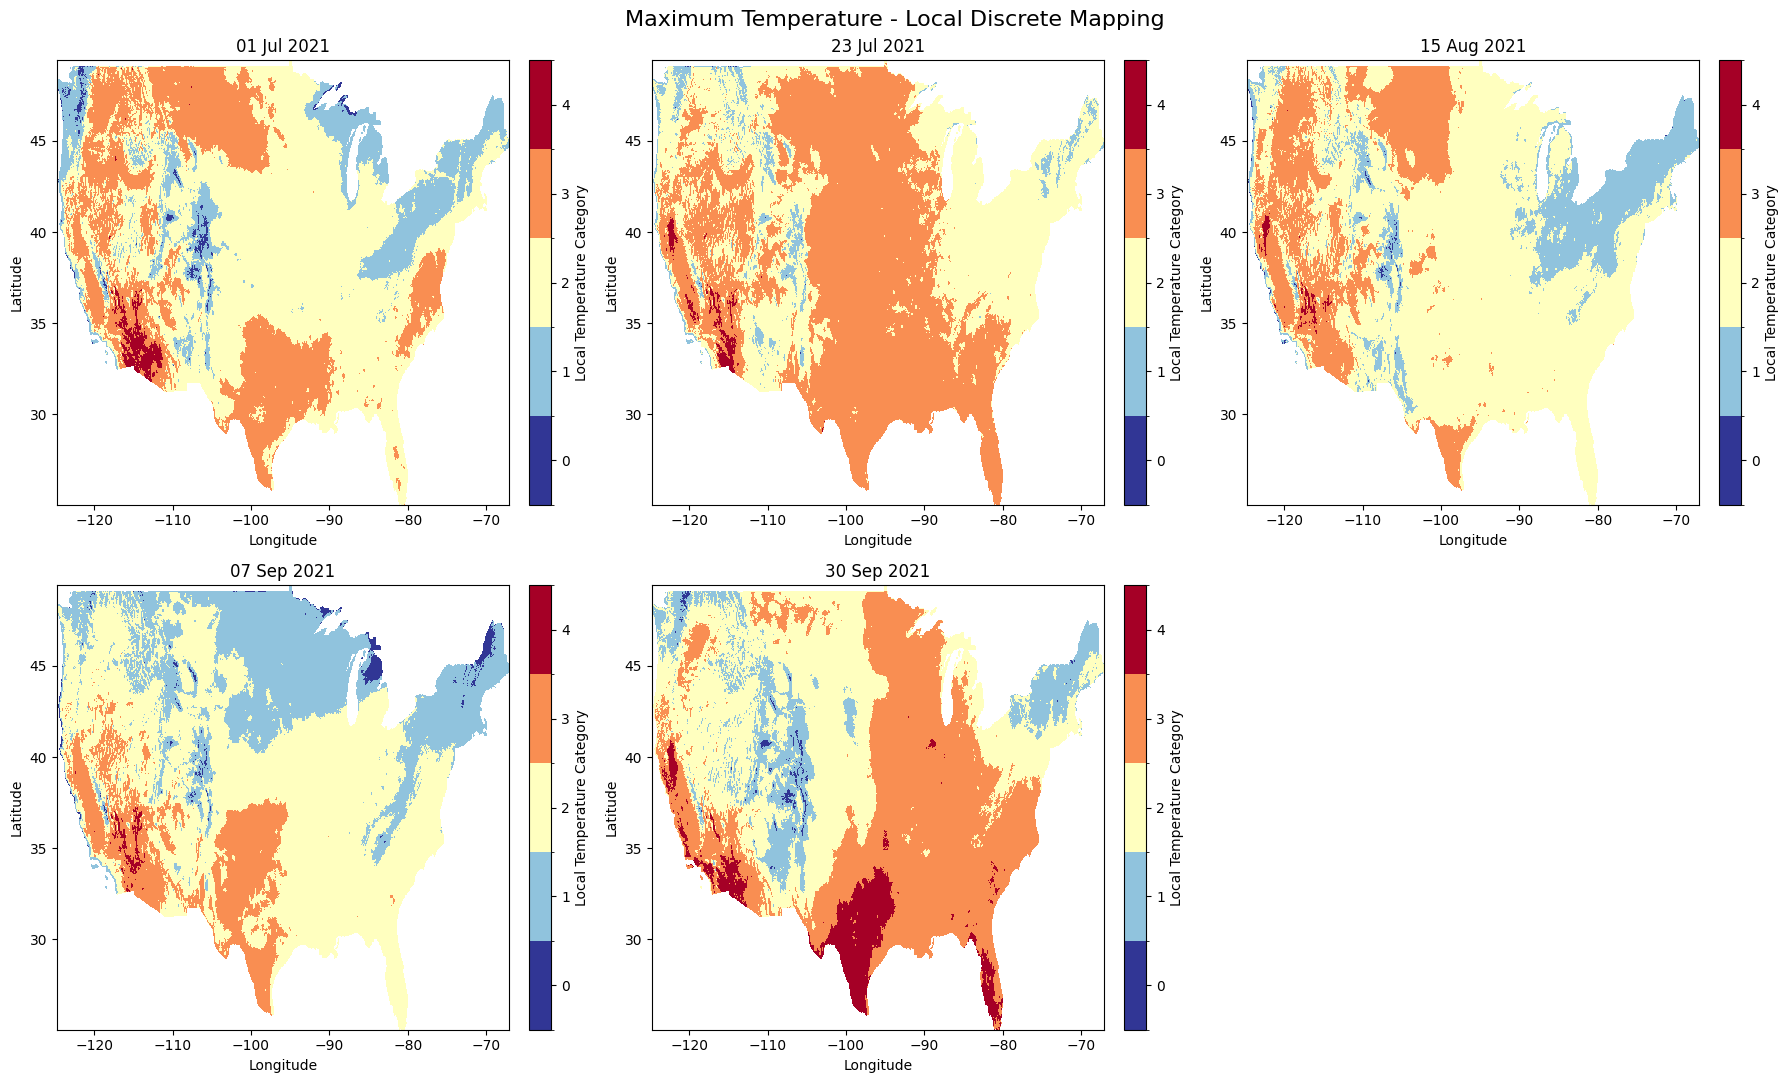

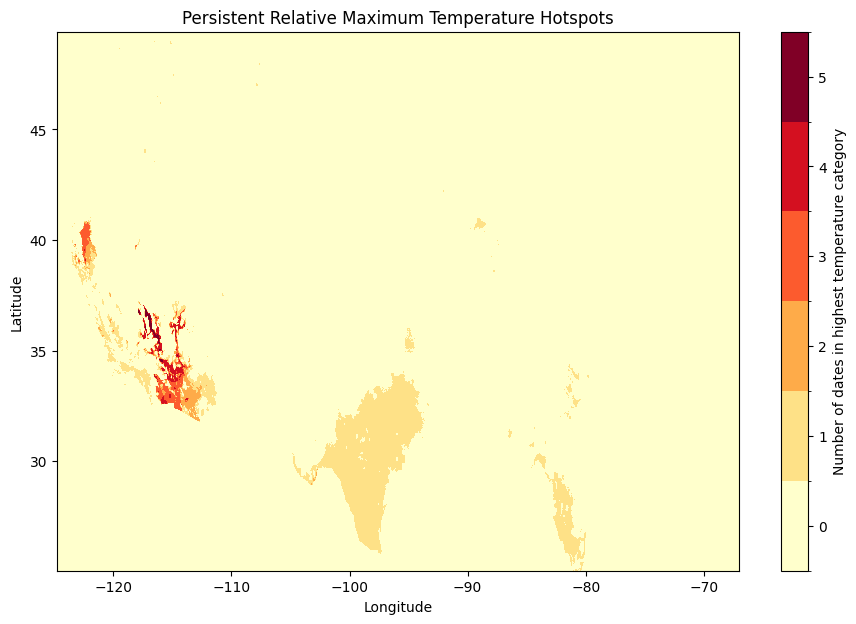

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

#LOCAL MAPPING USING DISCRETE COLOR MAPS

# Select the same 5 time instances
indices = np.linspace(0, len(tmmx.day) - 1, 5, dtype=int)

# Number of discrete temperature categories
num_bins = 5

# Store the highest-category mask for each date
highest_category_masks = []

# Create 3 + 2 subplot layout
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

# Plot local discrete maps
for i, idx in enumerate(indices):

    daily_data = tmmx.isel(day=idx)

    local_min = float(daily_data.min(skipna=True))
    local_max = float(daily_data.max(skipna=True))

    # Create 5 equally spaced local intervals
    levels = np.linspace(local_min, local_max, num_bins + 1)

    # Assign each grid cell to a category
    categories = xr.apply_ufunc(
        np.digitize,
        daily_data,
        input_core_dims=[[]],
        output_core_dims=[[]],
        kwargs={"bins": levels[1:-1]},
        vectorize=True,
        output_dtypes=[int]
    )

    # Mask missing values
    categories = categories.where(daily_data.notnull())

    # Identify cells in the highest category
    highest_category_masks.append(categories == num_bins - 1)

    # Plot discrete map
    cmap = plt.get_cmap("RdYlBu_r", num_bins)
    norm = mcolors.BoundaryNorm(
        np.arange(-0.5, num_bins + 0.5, 1),
        cmap.N
    )

    date = pd.to_datetime(tmmx.day.values[idx]).strftime("%d %b %Y")

    categories.plot(
        ax=axes[i],
        cmap=cmap,
        norm=norm,
        add_colorbar=False
    )

    axes[i].set_title(date)
    axes[i].set_xlabel("Longitude")
    axes[i].set_ylabel("Latitude")

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    fig.colorbar(
        sm,
        ax=axes[i],
        ticks=range(num_bins),
        label="Local Temperature Category",
        fraction=0.046,
        pad=0.04
    )

# Remove unused subplot
fig.delaxes(axes[5])

plt.suptitle(
    "Maximum Temperature - Local Discrete Mapping",
    fontsize=16
)

plt.tight_layout()
plt.savefig(
    "/kaggle/working/tmmx_local_discrete.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------
# Persistent relative temperature hotspot map
# ------------------------------------------------

# Count how many dates each grid cell was in the highest category
hotspot_count = sum(highest_category_masks)

# Plot persistence map
plt.figure(figsize=(11, 7))

hotspot_count.plot(
    cmap="YlOrRd",
    vmin=0,
    vmax=5,
    levels=np.arange(-0.5, 6, 1),
    cbar_kwargs={
        "label": "Number of dates in highest temperature category",
        "ticks": range(6)
    }
)

plt.title("Persistent Relative Maximum Temperature Hotspots")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.savefig(
    "/kaggle/working/tmmx_persistent_hotspots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

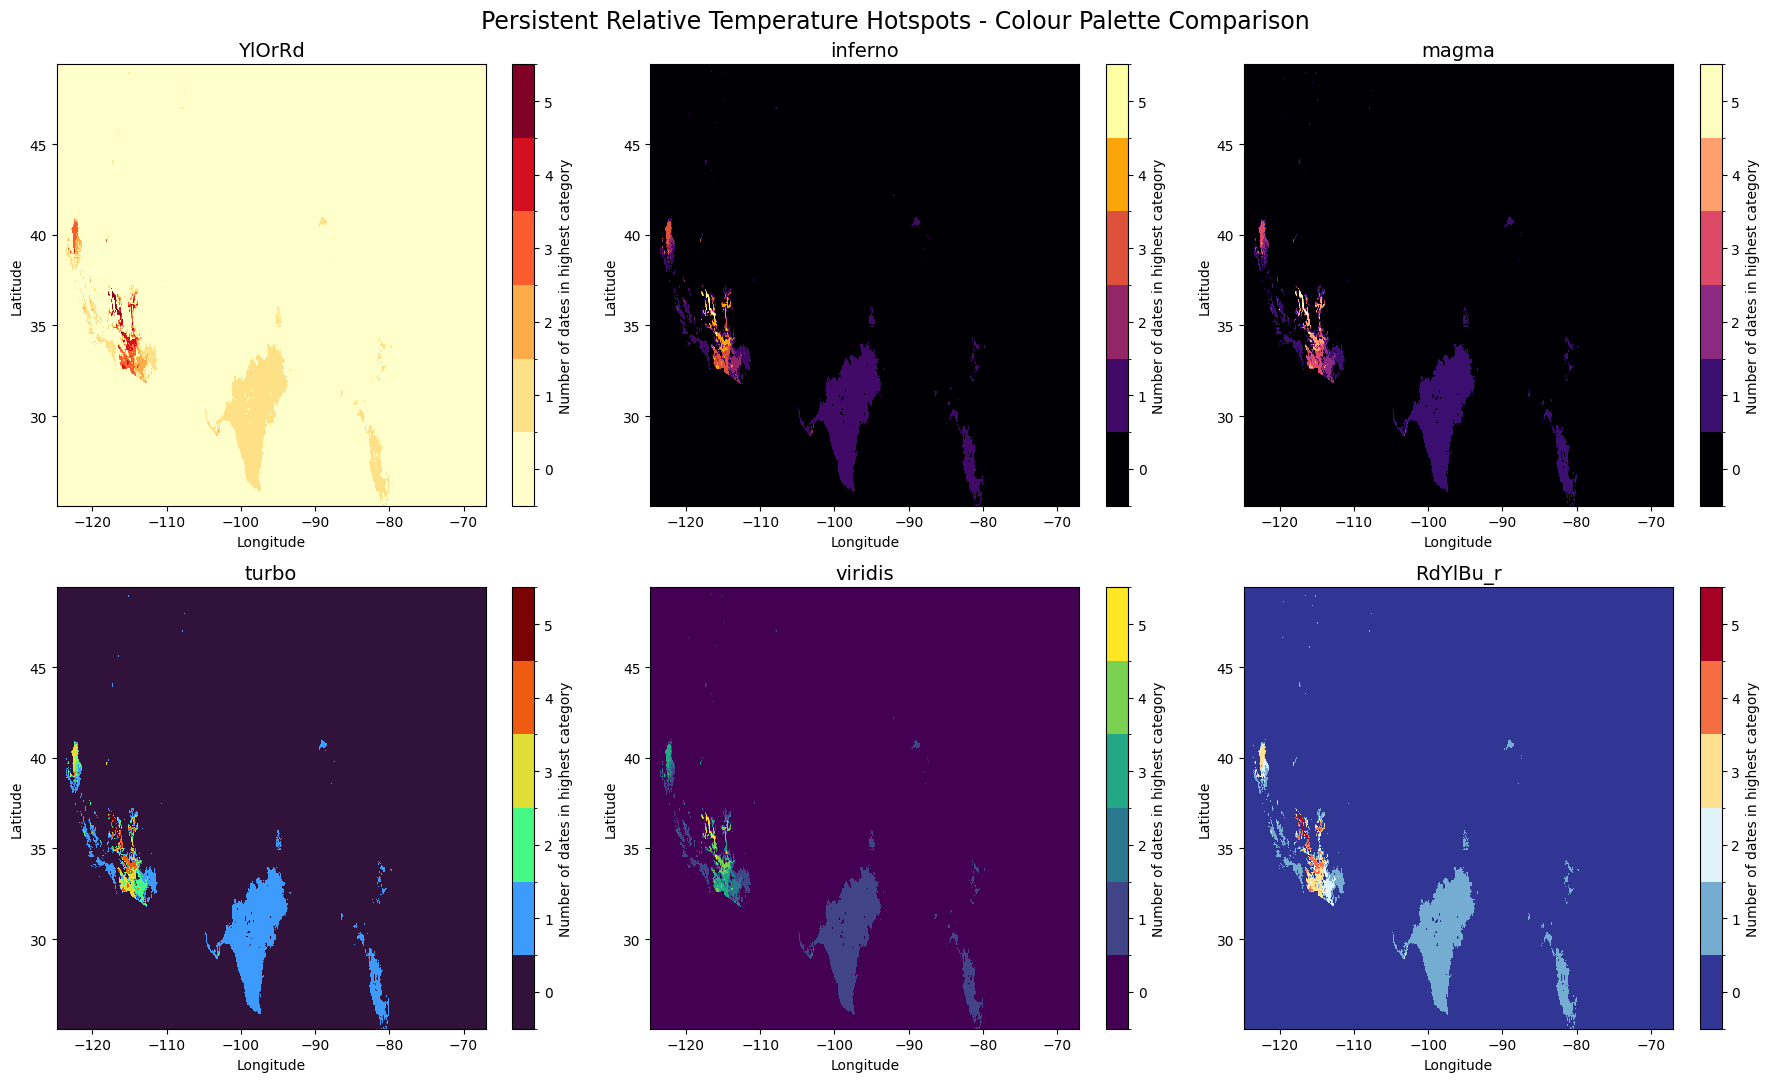

In [68]:
import matplotlib.pyplot as plt

import numpy as np
import xarray as xr

#HOTSPOTS WITH DIFF COLOR PALETTES
# Colour palettes to compare
palettes = [
    "YlOrRd",
    "inferno",
    "magma",
    "turbo",
    "viridis",
    "RdYlBu_r"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, palette in enumerate(palettes):

    hotspot_count.plot(
        ax=axes[i],
        cmap=palette,
        vmin=0,
        vmax=5,
        levels=np.arange(-0.5, 6, 1),
        add_colorbar=True,
        cbar_kwargs={
            "label": "Number of dates in highest category",
            "ticks": range(6)
        }
    )

    axes[i].set_title(palette, fontsize=14)
    axes[i].set_xlabel("Longitude")
    axes[i].set_ylabel("Latitude")

plt.suptitle(
    "Persistent Relative Temperature Hotspots - Colour Palette Comparison",
    fontsize=17
)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/tmmx_palette_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

SRAD- Solar Radiation

In [69]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load solar radiation dataset
file_path = "/kaggle/input/datasets/dayanithaam/gridmet/srad_2021.nc"

ds_srad = xr.open_dataset(file_path)

srad = ds_srad["surface_downwelling_shortwave_flux_in_air"].sel(
    day=slice("2021-07-01", "2021-09-30")
)

print("Shape:", srad.shape)
print("Units:", srad.attrs.get("units"))
print("Minimum:", float(srad.min()))
print("Maximum:", float(srad.max()))
print("Mean:", float(srad.mean()))

Shape: (92, 585, 1386)
Units: W m-2
Minimum: 29.3
Maximum: 450.90000000000003
Mean: 254.6866360611848


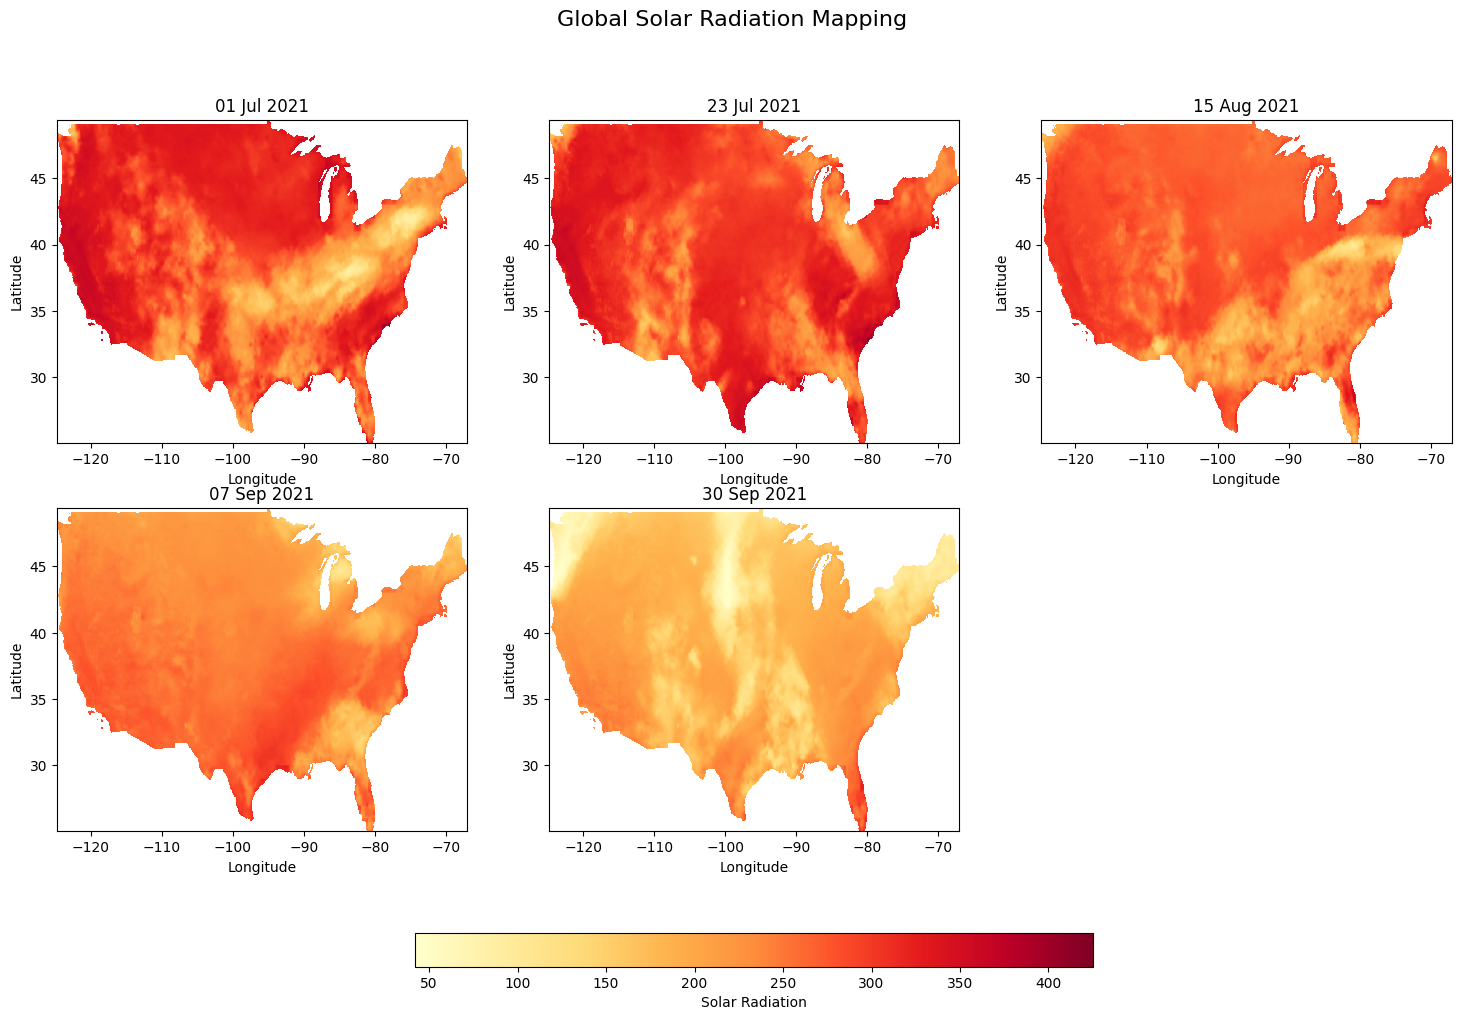

In [70]:
#GLOBAL MAPPING
global_min = float(srad.isel(day=indices).min())
global_max = float(srad.isel(day=indices).max())

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, idx in enumerate(indices):
    daily_data = srad.isel(day=idx)

    date = pd.to_datetime(srad.day.values[idx]).strftime("%d %b %Y")

    img = daily_data.plot(
        ax=axes[i],
        cmap="YlOrRd",
        vmin=global_min,
        vmax=global_max,
        add_colorbar=False
    )

    axes[i].set_title(date)
    axes[i].set_xlabel("Longitude")
    axes[i].set_ylabel("Latitude")

fig.delaxes(axes[5])

fig.colorbar(
    img, ax=axes[:5],
    orientation="horizontal",
    fraction=0.04,
    pad=0.12,
    label="Solar Radiation"
)

plt.suptitle("Global Solar Radiation Mapping", fontsize=16)

plt.savefig("/kaggle/working/srad_global.png", dpi=300, bbox_inches="tight")
plt.show()

Date with highest average solar radiation: 05 July 2021
Highest daily average: 305.9935339206703


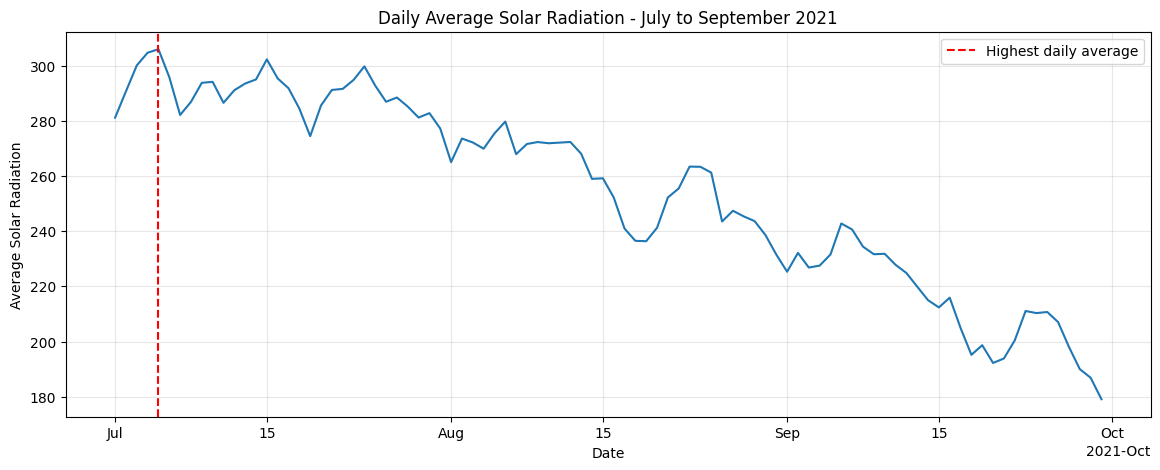

In [71]:
#AVERAGE MAPPING
daily_srad_avg = srad.mean(dim=["lat", "lon"], skipna=True)

hottest_idx = daily_srad_avg.argmax(dim="day").item()

print("Date with highest average solar radiation:",
      pd.to_datetime(srad.day.values[hottest_idx]).strftime("%d %B %Y"))

print("Highest daily average:", float(daily_srad_avg.max()))

plt.figure(figsize=(14, 5))

daily_srad_avg.plot()

plt.axvline(
    x=srad.day.values[hottest_idx],
    color="red",
    linestyle="--",
    label="Highest daily average"
)

plt.title("Daily Average Solar Radiation - July to September 2021")
plt.xlabel("Date")
plt.ylabel("Average Solar Radiation")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("/kaggle/working/srad_daily_average.png",
            dpi=300, bbox_inches="tight")

plt.show()

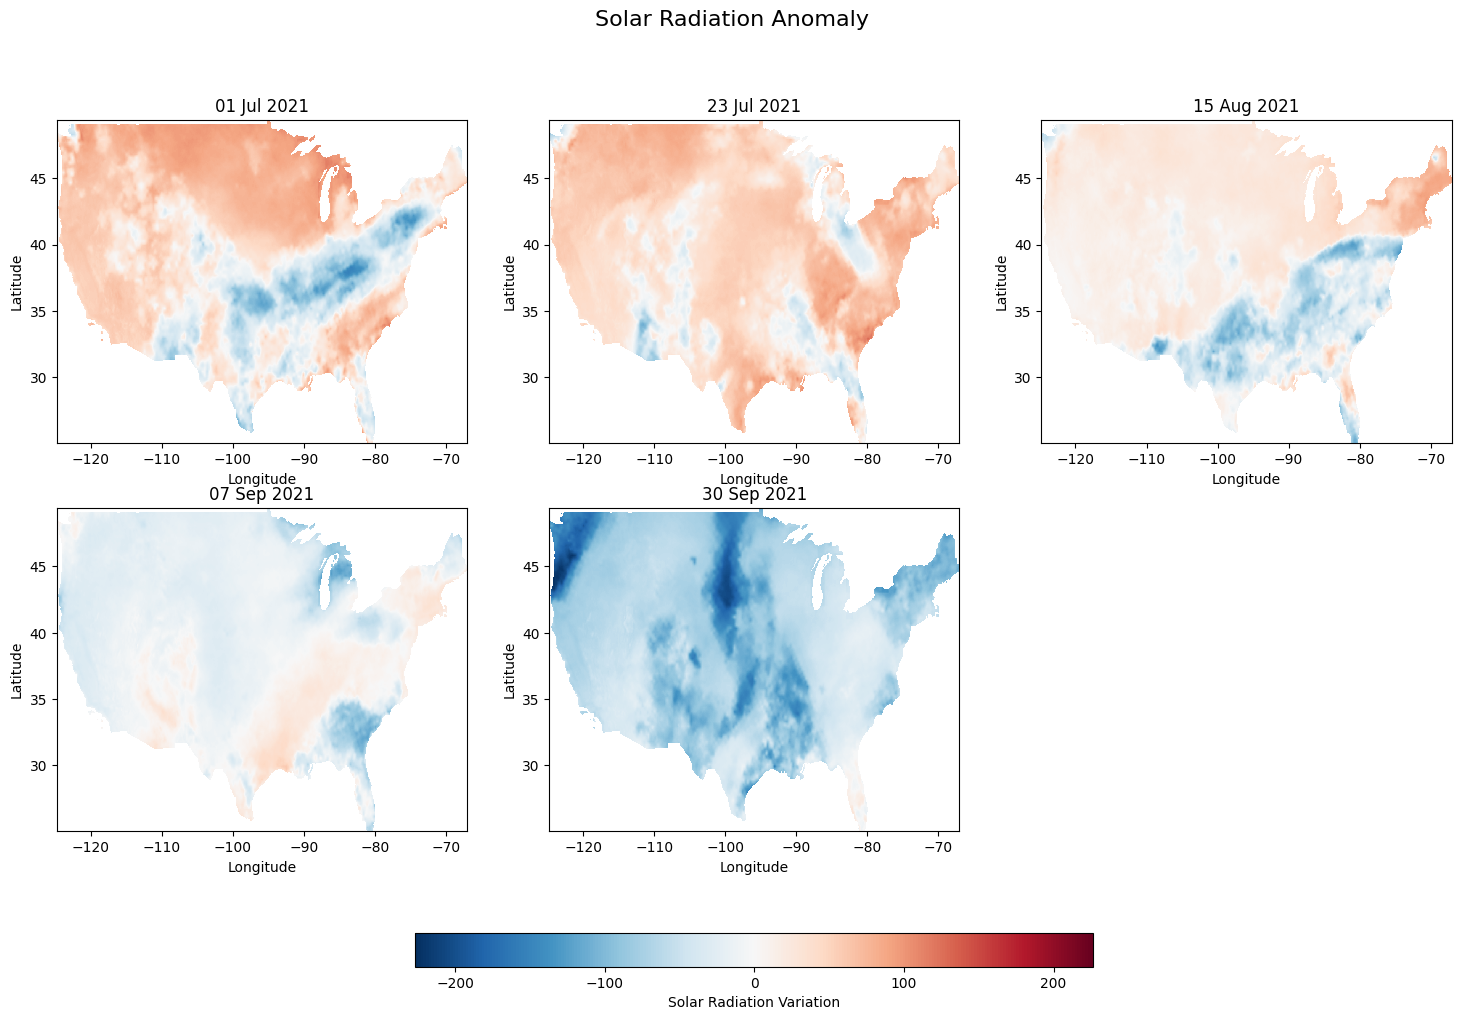

In [72]:
#ANOMALY MAPPING (value-average)
# Calculate temporal mean at each grid cell
srad_mean = srad.mean(dim="day", skipna=True)

# Calculate anomalies for the 5 selected dates
srad_anomaly = srad.isel(day=indices) - srad_mean

# Symmetric colour scale centred at zero
max_abs = float(abs(srad_anomaly).max())

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, idx in enumerate(indices):

    anomaly = srad_anomaly.isel(day=i)

    date = pd.to_datetime(srad.day.values[idx]).strftime("%d %b %Y")

    img = anomaly.plot(
        ax=axes[i],
        cmap="RdBu_r",
        vmin=-max_abs,
        vmax=max_abs,
        add_colorbar=False
    )

    axes[i].set_title(date)
    axes[i].set_xlabel("Longitude")
    axes[i].set_ylabel("Latitude")

fig.delaxes(axes[5])

fig.colorbar(
    img, ax=axes[:5],
    orientation="horizontal",
    fraction=0.04,
    pad=0.12,
    label="Solar Radiation Variation"
)

plt.suptitle("Solar Radiation Anomaly", fontsize=16)

plt.savefig("/kaggle/working/srad_anomaly.png", dpi=300, bbox_inches="tight")
plt.show()

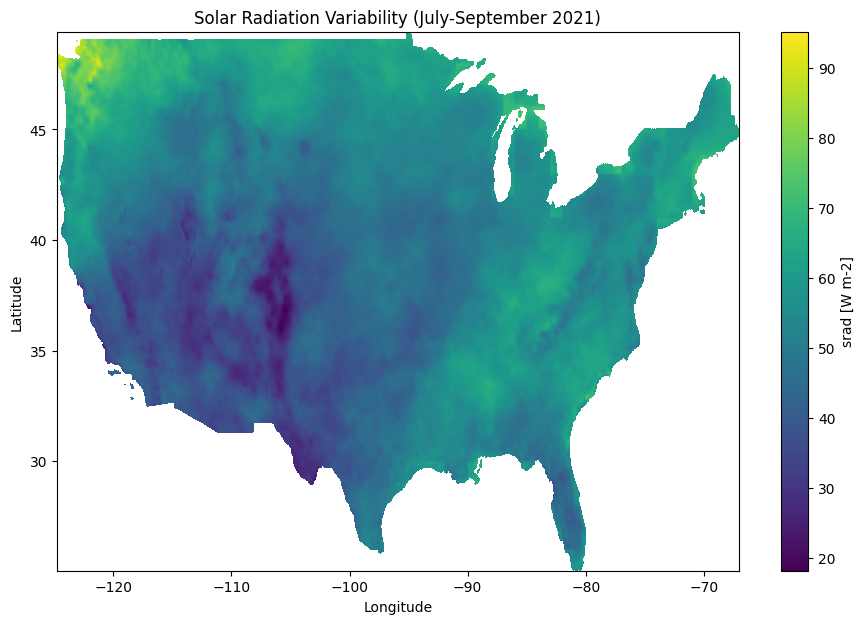

In [73]:
#variability
srad_std = srad.std(dim="day", skipna=True)

plt.figure(figsize=(11, 7))

srad_std.plot(cmap="viridis")

plt.title("Solar Radiation Variability (July-September 2021)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.savefig("/kaggle/working/srad_variability.png",
            dpi=300, bbox_inches="tight")

plt.show()

PRECIPITATION

In [74]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load precipitation dataset
file_path = "/kaggle/input/datasets/dayanithaam/gridmet/pr_2021.nc"

ds_pr = xr.open_dataset(file_path)

print(ds_pr)
print(ds_pr["precipitation_amount"].attrs)

# Extract July-September 2021
pr = ds_pr["precipitation_amount"].sel(
    day=slice("2021-07-01", "2021-09-30")
)

# Select 5 evenly spaced dates
indices = np.linspace(0, len(pr.day) - 1, 5, dtype=int)

# Inspect values
print("Shape:", pr.shape)
print("Units:", pr.attrs.get("units"))
print("Minimum:", float(pr.min()))
print("Maximum:", float(pr.max()))
print("Mean:", float(pr.mean()))
print("Missing values:", int(pr.isnull().sum()))

<xarray.Dataset> Size: 2GB
Dimensions:               (day: 365, lat: 585, lon: 1386, crs: 1)
Coordinates:
  * day                   (day) datetime64[ns] 3kB 2021-01-01 ... 2021-12-31
  * lat                   (lat) float64 5kB 49.4 49.36 49.32 ... 25.11 25.07
  * lon                   (lon) float64 11kB -124.8 -124.7 ... -67.1 -67.06
  * crs                   (crs) uint16 2B 3
Data variables:
    precipitation_amount  (day, lat, lon) float64 2GB ...
Attributes: (12/19)
    geospatial_bounds_crs:      EPSG:4326
    Conventions:                CF-1.6
    geospatial_bounds:          POLYGON((-124.7666666333333 49.40000000000000...
    geospatial_lat_min:         25.066666666666666
    geospatial_lat_max:         49.40000000000000
    geospatial_lon_min:         -124.7666666333333
    ...                         ...
    date:                       30 March 2023
    note1:                      The projection information for this file is: ...
    note2:                      Citation: Abatzog

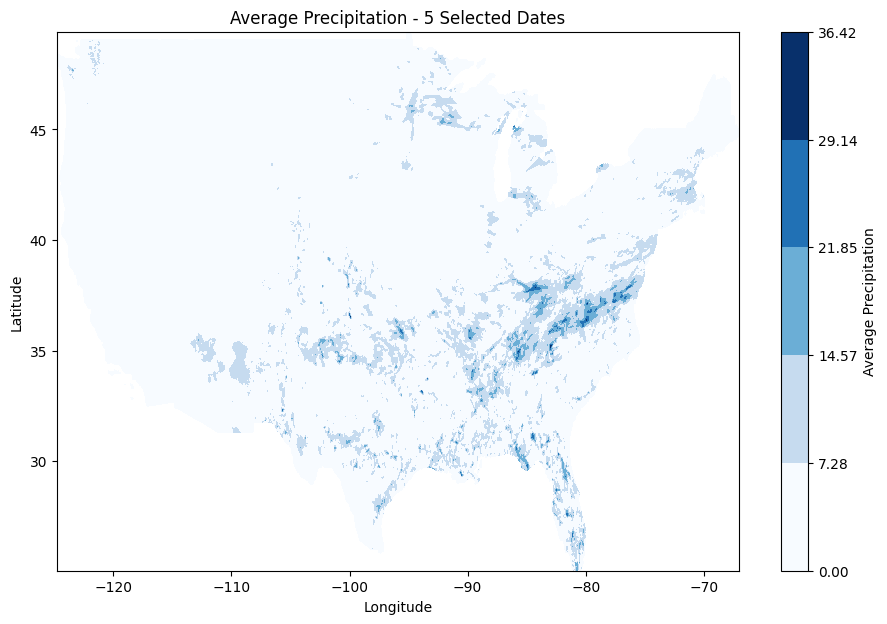

In [75]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Average precipitation across the 5 selected dates
pr_avg = pr.isel(day=indices).mean(dim="day", skipna=True)

# Create 5 discrete categories
levels = np.linspace(
    float(pr_avg.min()),
    float(pr_avg.max()),
    6
)

cmap = plt.get_cmap("Blues", 5)
norm = mcolors.BoundaryNorm(levels, cmap.N)

# Plot
plt.figure(figsize=(11, 7))

pr_avg.plot(
    cmap=cmap,
    norm=norm,
    cbar_kwargs={
        "label": "Average Precipitation",
        "ticks": levels
    }
)

plt.title("Average Precipitation - 5 Selected Dates")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.savefig(
    "/kaggle/working/pr_average_discrete.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

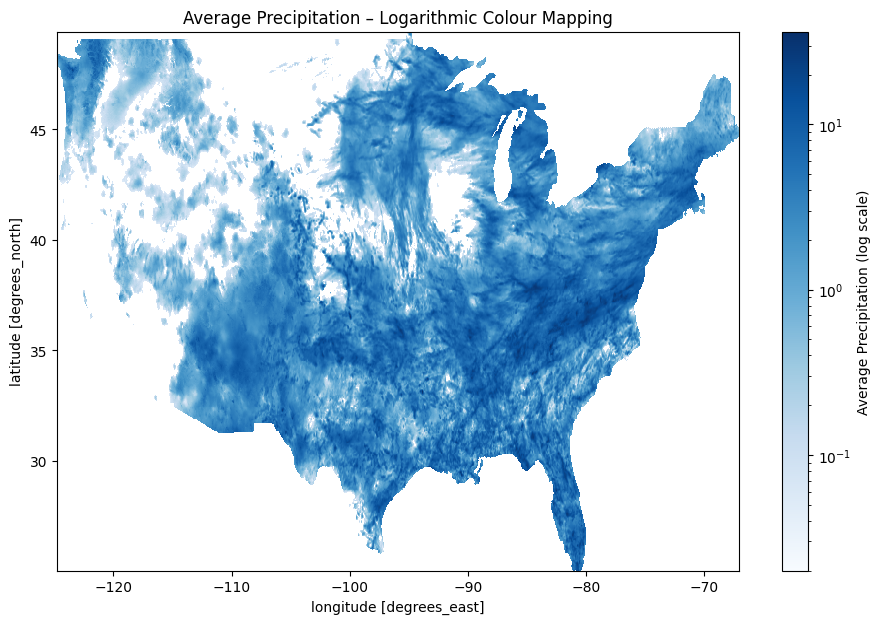

In [81]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# Average precipitation across the selected dates
pr_avg = pr.isel(day=indices).mean(dim="day", skipna=True)

# Mask zero and negative values
pr_positive = pr_avg.where(pr_avg > 0)

vmin = float(pr_positive.min())
vmax = float(pr_positive.max())

plt.figure(figsize=(11, 7))

pr_positive.plot(
    cmap="Blues",
    norm=mcolors.LogNorm(vmin=vmin, vmax=vmax),
    cbar_kwargs={"label": "Average Precipitation (log scale)"}
)

plt.title("Average Precipitation – Logarithmic Colour Mapping")
plt.savefig(
    "/kaggle/working/pr_averagelog.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

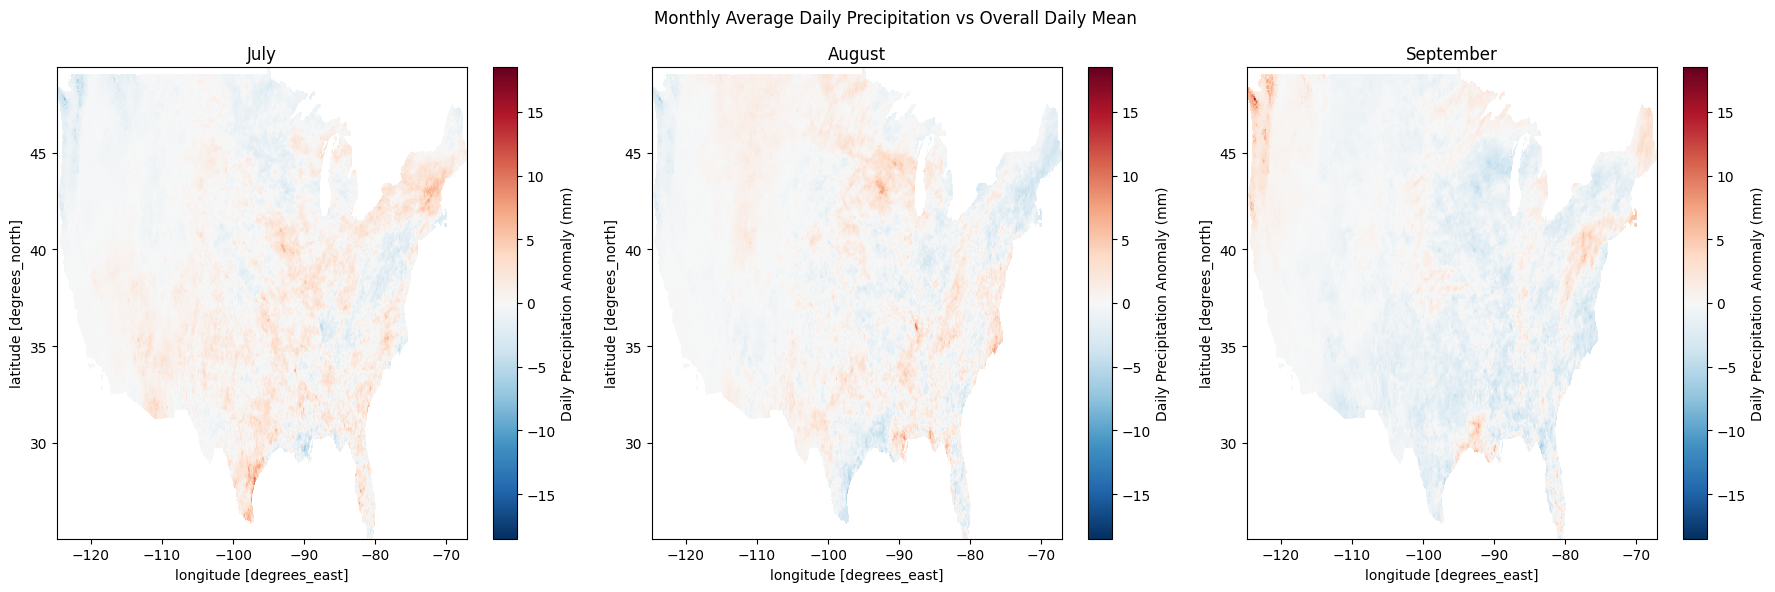

In [78]:
import matplotlib.pyplot as plt
import pandas as pd

# Average daily precipitation for each month
monthly_avg = pr.resample(day="MS").mean()

# Overall daily average across July, August and September
overall_mean = pr.mean(dim="day")

# Monthly anomalies
monthly_anomaly = monthly_avg - overall_mean

# Common colour scale
max_abs = float(abs(monthly_anomaly).max())

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i in range(3):
    month = pd.to_datetime(
        monthly_avg.day.values[i]
    ).strftime("%B")

    monthly_anomaly.isel(day=i).plot(
        ax=axes[i],
        cmap="RdBu_r",
        vmin=-max_abs,
        vmax=max_abs,
        cbar_kwargs={"label": "Daily Precipitation Anomaly (mm)"}
    )

    axes[i].set_title(f"{month}")

plt.suptitle("Monthly Average Daily Precipitation vs Overall Daily Mean")
plt.tight_layout()
plt.savefig(
    "/kaggle/working/pr_monthlyanomaly.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()